[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Elheims/scikit-learn-cookbook/blob/main/12.%20Cross-Validation%20and%20Model%20Evaluation%20Techniques/ch12_cross_validation.ipynb)

# Chapter 12: Cross-Validation and Model Evaluation Techniques

**Book:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt) — Chapter 12, pp. 336–353

**What you will learn in this chapter:**
- Why a single train/test split is an unreliable estimate and how k-fold and stratified k-fold cross-validation (CV) fix it
- Leave-one-out CV (LOOCV) and **nested** CV, and the two traps they address: selection bias and data leakage
- The high-level API: `cross_val_score`, `cross_validate`, `GridSearchCV`, `RandomizedSearchCV`
- How to select a model and its hyper-parameters without fooling yourself
- How to diagnose over- and under-fitting with learning curves and validation curves
- Practical exercises: cross-validating a classifier, tuning with grid search, and diagnosing generalisation

## Chapter summary

| Section | Core idea | Key API |
|---|---|---|
| Introduction to cross-validation | Average the score over *k* train/validation splits | `KFold`, `StratifiedKFold` |
| Advanced methods | LOOCV (n folds of size 1) and nested CV (tune inside, evaluate outside) | `LeaveOneOut`, `GridSearchCV` inside `cross_val_score` |
| Implementing CV in scikit-learn | One call per task: one metric, several metrics, tuning | `cross_val_score`, `cross_validate`, `GridSearchCV` |
| Model selection | Exhaustive vs random hyper-parameter search, then a final test | `GridSearchCV`, `RandomizedSearchCV` |
| Evaluating generalizability | Score vs training size, score vs hyper-parameter | `learning_curve`, `validation_curve` |
| Practical exercises | Multi-metric CV, grid search, curves | — |

**How this notebook is organised.** Each section has a summary, the book's code reproduced and executed, a verification against the numbers and figures printed in the book, and a *Theory* cell.
Cells marked **Extension** are not in the book's code. Places where the book's text or code is inaccurate or incomplete are flagged with **Book correction** (collected again at the end).
The book's introduction announces a recipe "Model evaluation metrics overview" that does not exist in the chapter; the metrics overview is therefore added as an extension of Section 3.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display

print("scikit-learn version:", sklearn.__version__)
print("NumPy version       :", np.__version__)

scikit-learn version: 1.9.1
NumPy version       : 2.5.3


## 1. Introduction to cross-validation

**Summary.** A model must be judged on data it has not seen, but a *single* train/test split gives one noisy number that depends on which rows landed where. **Cross-validation** splits the data into *k* subsets (**folds**), trains on *k − 1* of them, scores on the remaining one, repeats *k* times and averages — every observation is used for validation exactly once. The *k* in k-fold is unrelated to the *k* of K-means or k-NN.

### Getting ready
A synthetic binary classification dataset: 500 samples, 10 features (8 informative, 2 redundant).

In [2]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [3]:
X, y = make_classification(
    n_samples=500, n_features=10, n_informative=8,
    n_redundant=2, n_classes=2, random_state=2024
)
print("X:", X.shape, "| class counts:", np.bincount(y))

X: (500, 10) | class counts: [250 250]


### How to do it…
k-fold with shuffling, then stratified k-fold:

In [4]:
kf = KFold(n_splits=5, shuffle=True, random_state=2024)

In [5]:
accuracies = []
for train_index, test_index in kf.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    model = LogisticRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracies.append(accuracy_score(y_test, y_pred))
print(f"Average accuracy (KFold): "
      f"{np.mean(accuracies):.3f}")
print("per-fold accuracies:", np.round(accuracies, 3))

Average accuracy (KFold): 0.756
per-fold accuracies: [0.72 0.72 0.88 0.71 0.75]


In [6]:
strat_kf = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=2024)
strat_accuracies = []
for train_index, test_index in strat_kf.split(X, y):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    model = LogisticRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    strat_accuracies.append(accuracy_score(y_test, y_pred))
print(f"Average accuracy (StratifiedKFold): "
      f"{np.mean(strat_accuracies):.3f}")
print("per-fold accuracies:", np.round(strat_accuracies, 3))

Average accuracy (StratifiedKFold): 0.766
per-fold accuracies: [0.79 0.76 0.76 0.76 0.76]


**Verification against the book:** the printed outputs — `Average accuracy (KFold): 0.756` and `Average accuracy (StratifiedKFold): 0.766` — are reproduced exactly ✔.

The book concludes that "using stratified k-folds actually elicits a slightly higher accuracy, which is good news since the methodology is designed to make each fold more representative". That reading is not supported: look at the *per-fold* accuracies — 0.71 to 0.88 for k-fold, 0.76 to 0.79 for stratified k-fold. A 1-point difference between two averages whose folds spread over 17 points is noise, and this dataset is **perfectly balanced** (250 / 250), where stratification has almost nothing to do. Both statements are tested below.

### How it works…
Standard k-fold cuts the data into *k* (almost) equal parts, trains on *k − 1*, tests on the remaining one, *k* times. In classification, with imbalanced classes, random folds can misrepresent the class proportions; **stratified** k-fold preserves each class's percentage in every fold.

**Extension 1 — when stratification matters.** A 100-sample dataset with only ~10 positives. How many positives does each of the five test folds get?

In [7]:
Xi, yi = make_classification(n_samples=100, n_features=5, weights=[0.9, 0.1], flip_y=0, random_state=2024)
print("class counts:", np.bincount(yi))
for name, cv in [("KFold (shuffled)", KFold(5, shuffle=True, random_state=2024)), ("StratifiedKFold", StratifiedKFold(5, shuffle=True, random_state=2024))]:
    print(f"{name:18s} positives per test fold:", [int(yi[te].sum()) for _, te in cv.split(Xi, yi)])

empty = sum(any(yi[te].sum() == 0 for _, te in KFold(5, shuffle=True, random_state=s).split(Xi)) for s in range(200))
print(f"\nover 200 different shuffles, plain KFold produced a test fold with NO positive example in {empty} of them "
      f"({empty / 200:.0%}); StratifiedKFold never does (it keeps 2 per fold)")

class counts: [90 10]
KFold (shuffled)   positives per test fold: [4, 0, 2, 1, 3]
StratifiedKFold    positives per test fold: [2, 2, 2, 2, 2]

over 200 different shuffles, plain KFold produced a test fold with NO positive example in 75 of them (38%); StratifiedKFold never does (it keeps 2 per fold)


Plain k-fold produced test folds with 4, **0**, 2, 1 and 3 positives — one fold has *no* positive example at all, so its precision, recall and ROC-AUC are undefined — while stratified k-fold gave exactly 2 per fold. Over 200 different shuffles, **38%** of plain k-fold splits contained at least one fold without a single positive. Stratification is therefore not a cosmetic refinement for rare classes.

**Extension 2 — is 0.756 vs 0.766 a real difference?** Repeat both cross-validations with 300 different shuffles and look at the spread of the *estimates* themselves:

       KFold  StratifiedKFold
mean  0.7698           0.7710
std   0.0057           0.0062
min   0.7540           0.7540
max   0.7860           0.7860


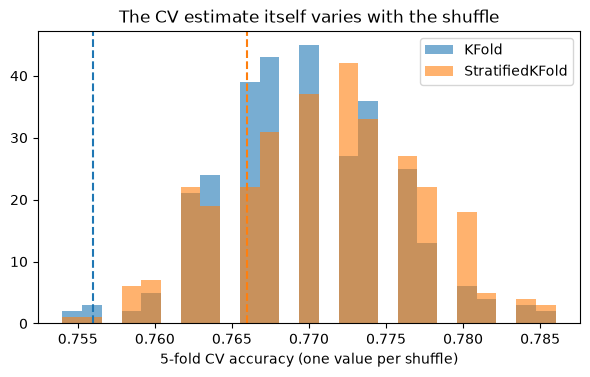

In [8]:
from sklearn.model_selection import cross_val_score

est_kf = [cross_val_score(LogisticRegression(), X, y, cv=KFold(5, shuffle=True, random_state=s)).mean() for s in range(300)]
est_sk = [cross_val_score(LogisticRegression(), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=s)).mean() for s in range(300)]
print(pd.DataFrame({"KFold": est_kf, "StratifiedKFold": est_sk}).describe().loc[["mean", "std", "min", "max"]].round(4))

plt.figure(figsize=(7, 3.8))
plt.hist(est_kf, bins=25, alpha=0.6, label="KFold"); plt.hist(est_sk, bins=25, alpha=0.6, label="StratifiedKFold")
plt.axvline(0.756, color="C0", ls="--"); plt.axvline(0.766, color="C1", ls="--")
plt.xlabel("5-fold CV accuracy (one value per shuffle)"); plt.legend(); plt.title("The CV estimate itself varies with the shuffle"); plt.show()

Across 300 shuffles both estimators average **0.770** (0.7698 vs 0.7710) with a standard deviation of ≈ 0.006 and the same range (0.754–0.786): on balanced data, stratification changes nothing. The book's 0.756 and 0.766 are two ordinary draws from this spread (the first at its low end); their 0.010 gap is ≈ 1.6 standard deviations of the shuffle-to-shuffle noise, and the "true" 5-fold estimate is about 0.77. The book's "stratified is better" is an artefact of one seed. The right habit is to report the mean *and* the spread (or repeat the CV) and to use stratification where it provably matters — rare classes (above).

### Theory — cross-validation
* **Why:** the score on one split is a random variable; CV averages *k* of them, using all the data for training *and* validation (not at the same time). The standard deviation over folds shows how much the estimate can be trusted.
* **Bias–variance of the estimator:** small *k* (e.g. 2–3) trains on less data (pessimistic bias); large *k* (10, LOOCV) has low bias but more correlated, costlier fits. 5 or 10 is the usual compromise.
* **Stratification** keeps class proportions in every fold: essential for rare classes (otherwise a fold may have no positive example), nearly irrelevant for balanced data. `cv=5` with a classifier already stratifies (Section 3).
* **Repeating** the CV with different shuffles (`RepeatedKFold`, `RepeatedStratifiedKFold`) averages out the luck of one partition.
* **CV estimates generalisation of the *procedure*** (model + preprocessing + tuning), not of one fitted model — which is why all steps must happen inside each fold (Section 2).

### Hands-on workflow (book)
Choose a classification dataset, inspect the class balance, apply `KFold()` and `StratifiedKFold()`, train a `LogisticRegression()` in each fold, evaluate it with `accuracy_score` (or another metric) and compare the consistency of both strategies — as above.

## 2. Advanced cross-validation methods

**Summary.** For small datasets or tuned models two refinements are used: **leave-one-out CV (LOOCV)** (every sample is a validation set of size 1: nearly unbiased, expensive) and **nested CV** (an *inner* loop selects hyper-parameters, an *outer* loop evaluates the whole procedure, so the evaluation is not contaminated by the tuning).

### Getting ready
The diabetes dataset (442 patients, 10 features, a *quantitative* measure of disease progression) and Ridge regression, which benefits from tuning its penalty.

In [9]:
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import (
    LeaveOneOut, GridSearchCV, cross_val_score)
from sklearn.linear_model import Ridge

In [10]:
data = load_diabetes()
X = data.data
y = data.target
print("X:", X.shape, "| target mean/std/variance:", y.mean().round(1), y.std().round(1), y.var().round(1))

X: (442, 10) | target mean/std/variance: 152.1 77.0 5929.9


> **Book correction (target type).** The book describes the diabetes target as "a *qualitative* target variable representing disease progression". It is a **quantitative** (continuous) measure, ranging from 25 to 346; that is why it is a regression task.

### How to do it…
**1. LOOCV** with a fixed `Ridge(alpha=1.0)`, scored by (negative) mean squared error:

In [11]:
loo = LeaveOneOut()
model = Ridge(alpha=1.0)
scores = cross_val_score(
    model, X, y, cv=loo,
    scoring="neg_mean_squared_error"
)
print(f"LOOCV mean MSE: {-np.mean(scores):.3f}")
print("number of folds (= number of samples):", len(scores))

LOOCV mean MSE: 3327.655
number of folds (= number of samples): 442


In [12]:
param_grid = {"alpha": [0.01, 0.1, 1, 10, 100]}

In [13]:
nested_scores = cross_val_score(
    GridSearchCV(Ridge(), param_grid, cv=5),
    X, y, cv=5
)
print(f"Nested CV mean score: {np.mean(nested_scores):.3f}")

Nested CV mean score: 0.480


**Verification against the book:** `LOOCV mean MSE: 3327.655` ✔ and `Nested CV mean score: 0.480` ✔ — both reproduced exactly.

> **Book correction (what the 0.480 is, and "0.593 MSE").** After the output the book says "…since our final **0.593 MSE** is not much better than guessing". No 0.593 exists anywhere in the output. The nested-CV number **0.480 is an R²** (the default `score` of a regressor, *not* an MSE): the tuned Ridge explains **48% of the variance** of the target. Guessing the mean has R² = 0 and an MSE equal to the variance of `y` (5,930); the tuned model's MSE is ≈ 3,000 (computed below) — about half. "Not much better than guessing" is wrong, and 3,328 (LOOCV, `alpha=1`) vs 3,005 (tuned) shows that tuning `alpha` helped.

### How it works…
LOOCV trains on all points but one and tests on the held-out point, for every point: almost unbiased but expensive (442 fits here). Nested CV: the inner loop (`GridSearchCV`) selects hyper-parameters on the *training part of each outer fold*; the outer loop scores on data the tuning never saw.

**Extension 1 — the numbers in the same units.** Nested CV reported as MSE as well as R², and the baseline of predicting the mean, plus the alphas the inner loops chose in each outer fold:

In [14]:
from sklearn.model_selection import cross_validate, KFold

res = cross_validate(GridSearchCV(Ridge(), param_grid, cv=5), X, y, cv=5, return_estimator=True,
                     scoring={"r2": "r2", "mse": "neg_mean_squared_error"})
print(f"nested CV: R2 = {res['test_r2'].mean():.3f} | MSE = {-res['test_mse'].mean():.1f}")
print("alpha chosen by the inner loop in each outer fold:", [e.best_params_["alpha"] for e in res["estimator"]])
print(f"baseline 'predict the mean': MSE = variance of y = {y.var():.1f}  ->  tuned model removes {1 - (-res['test_mse'].mean()) / y.var():.0%} of it")

rows = []
for a in param_grid["alpha"]:
    rows.append({"alpha": a, "5-fold R2": cross_val_score(Ridge(alpha=a), X, y, cv=KFold(5, shuffle=True, random_state=0)).mean(),
                 "LOOCV MSE": -cross_val_score(Ridge(alpha=a), X, y, cv=LeaveOneOut(), scoring="neg_mean_squared_error").mean()})
display(pd.DataFrame(rows).set_index("alpha").round(3))

nested CV: R2 = 0.480 | MSE = 3004.7
alpha chosen by the inner loop in each outer fold: [0.1, 0.01, 0.1, 0.1, 0.1]
baseline 'predict the mean': MSE = variance of y = 5929.9  ->  tuned model removes 49% of it


,5-fold R2,LOOCV MSE
alpha,,
0.01,0.489,3000.392
0.10,0.488,3004.617
1.00,0.420,3327.655
10.00,0.158,4851.098
100.00,0.021,5794.725


The nested estimate in both units: **R² 0.480, MSE 3,004.7** — the tuned Ridge removes 49% of the variance of the target. The inner loops chose `alpha = 0.1` in four outer folds and `0.01` in one (a stable choice). The table shows why tuning matters: the fixed `alpha = 1` of the LOOCV recipe has MSE 3,328 and R² 0.42, whereas `alpha` 0.01–0.1 gives MSE ≈ 3,000 and R² ≈ 0.49; at `alpha = 100` the model predicts almost the mean (R² 0.02, MSE 5,795 against a variance of 5,930). The book's LOOCV number belongs to an *untuned* model, so it cannot be compared with the nested number.

**Extension 2 — LOOCV vs k-fold, and a free LOOCV for Ridge.** LOOCV needs *n* fits, but for Ridge the leave-one-out errors have a closed form: `RidgeCV` (with its default `cv=None`) returns them from a single fit. Compare cost and value:

In [15]:
import time
from sklearn.linear_model import RidgeCV

rows = {}
for name, cv in [("5-fold", KFold(5, shuffle=True, random_state=0)), ("10-fold", KFold(10, shuffle=True, random_state=0)), ("LOOCV (442 fits)", LeaveOneOut())]:
    t0 = time.perf_counter()
    mse = -cross_val_score(Ridge(alpha=1.0), X, y, cv=cv, scoring="neg_mean_squared_error").mean()
    rows[name] = {"MSE (alpha=1)": mse, "seconds": time.perf_counter() - t0}
t0 = time.perf_counter()
rcv = RidgeCV(alphas=[1.0], store_cv_results=True).fit(X, y)            # efficient leave-one-out, one fit
rows["RidgeCV closed-form LOO"] = {"MSE (alpha=1)": rcv.cv_results_.mean(), "seconds": time.perf_counter() - t0}
display(pd.DataFrame(rows).T.round(4))

,MSE (alpha=1),seconds
5-fold,3407.0699,0.0132
10-fold,3357.4611,0.0242
LOOCV (442 fits),3327.6551,1.0168
RidgeCV closed-form LOO,3327.6551,0.0020


LOOCV, 10-fold and 5-fold agree within 2.5% (MSE 3,328 / 3,357 / 3,407; the fewer the folds, the more pessimistic, because each model trains on less data). LOOCV needed 442 fits (≈ 1 s here), while `RidgeCV` returns **the identical value (3,327.6551)** from a single fit in about 2 ms — a closed-form shortcut that exists for linear smoothers such as Ridge. For most other models LOOCV costs *n* fits.

**Extension 3 — selection bias: why tuning *and* evaluating on the same folds is optimistic.** Labels that are *pure noise* (no model can beat 50%). A grid search over 36 `SVC` configurations picks the one that happens to score best on the folds; its `best_score_` is therefore flattering, while nested CV (tune inside each training fold, evaluate outside) honestly returns ≈ 0.5:

In [16]:
from sklearn.svm import SVC

param_grid_svc = {"C": [0.1, 1, 10, 100, 1000, 10000], "gamma": [1e-4, 1e-3, 1e-2, 1e-1, 1, 10]}
best_scores, nested_means = [], []
for seed in range(15):
    rng = np.random.RandomState(seed)
    Xn = rng.normal(size=(60, 20)); yn = rng.randint(0, 2, 60)                       # no signal at all
    gs = GridSearchCV(SVC(), param_grid_svc, cv=5).fit(Xn, yn)
    best_scores.append(gs.best_score_)
    nested_means.append(cross_val_score(GridSearchCV(SVC(), param_grid_svc, cv=5), Xn, yn, cv=5).mean())
print(f"15 pure-noise datasets, 36 candidate configurations each:")
print(f"  mean GridSearchCV.best_score_ (tuned and scored on the same folds): {np.mean(best_scores):.3f}   (max {np.max(best_scores):.3f})")
print(f"  mean nested-CV score                                              : {np.mean(nested_means):.3f}   (chance = 0.5)")

15 pure-noise datasets, 36 candidate configurations each:
  mean GridSearchCV.best_score_ (tuned and scored on the same folds): 0.579   (max 0.733)
  mean nested-CV score                                              : 0.516   (chance = 0.5)


With no signal at all, the "tuned and scored on the same folds" number averages **0.579** (up to 0.733 on one dataset): a pure selection artefact — the maximum of 36 noisy scores on 60 samples. The nested estimate, **0.516**, is indistinguishable from chance, as it should be. The effect shrinks with more data and fewer candidates (the book's Ridge has 5 candidates and 442 samples, so it is small there) but is never zero: report a nested-CV score or evaluate once on an untouched test set.

**Extension 4 — data leakage: the most common CV mistake.** 100 samples, 2,000 *noise* features, random labels. Selecting the 20 "best" features on **all** the data and *then* cross-validating leaks the labels into every fold; doing the selection **inside** each training fold (a `Pipeline`) does not:

In [17]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import make_pipeline

rng = np.random.RandomState(0)
Xn = rng.normal(size=(100, 2000)); yn = rng.randint(0, 2, 100)

X_selected = SelectKBest(f_classif, k=20).fit_transform(Xn, yn)                                  # WRONG: uses all labels
wrong = cross_val_score(LogisticRegression(), X_selected, yn, cv=5).mean()
right = cross_val_score(make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression()), Xn, yn, cv=5).mean()   # selection inside each fold
print(f"selection before CV (leaky) : accuracy {wrong:.3f}")
print(f"selection inside the folds  : accuracy {right:.3f}   (the truth is 0.5: there is no signal)")

selection before CV (leaky) : accuracy 0.810
selection inside the folds  : accuracy 0.430   (the truth is 0.5: there is no signal)


Selecting the features *before* cross-validating gives **0.81** accuracy on random labels — the labels leaked into every fold through the selection step — while selecting *inside* each fold gives 0.43, consistent with chance (0.5 ± 0.05 with 100 samples). A 38-point improvement created from nothing: leakage is not a subtle effect. Every data-dependent step (scaling, imputation, selection, resampling) belongs in a `Pipeline`.

**Extension 5 — other splitters for other data structures.** The chapter covers only random splits. When rows are not independent, random folds leak: **groups** (several rows per patient/user) need `GroupKFold`, **time series** need `TimeSeriesSplit` (always validate on the future):

In [18]:
from sklearn.model_selection import GroupKFold, TimeSeriesSplit

groups = np.repeat([0, 1, 2, 3], 3)                 # 12 rows from 4 groups (e.g. patients)
for tr, te in GroupKFold(n_splits=4).split(np.zeros(12), groups=groups):
    print("GroupKFold      test rows:", te, "-> group", set(groups[te]), "| train groups:", sorted(set(groups[tr])))
print()
for tr, te in TimeSeriesSplit(n_splits=3).split(np.zeros(12)):
    print("TimeSeriesSplit train rows:", tr, "| test rows:", te)

GroupKFold      test rows: [ 9 10 11] -> group {np.int64(3)} | train groups: [np.int64(0), np.int64(1), np.int64(2)]
GroupKFold      test rows: [6 7 8] -> group {np.int64(2)} | train groups: [np.int64(0), np.int64(1), np.int64(3)]
GroupKFold      test rows: [3 4 5] -> group {np.int64(1)} | train groups: [np.int64(0), np.int64(2), np.int64(3)]
GroupKFold      test rows: [0 1 2] -> group {np.int64(0)} | train groups: [np.int64(1), np.int64(2), np.int64(3)]

TimeSeriesSplit train rows: [0 1 2] | test rows: [3 4 5]
TimeSeriesSplit train rows: [0 1 2 3 4 5] | test rows: [6 7 8]
TimeSeriesSplit train rows: [0 1 2 3 4 5 6 7 8] | test rows: [ 9 10 11]


### There's more… (book hands-on)
The book's workflow: choose a regression dataset, apply `LeaveOneOut()` to a baseline, set up a hyper-parameter grid for Ridge, tune with `GridSearchCV()`, nest it in `cross_val_score()`, and compare LOOCV with nested CV in performance and cost. (Done above, with the corrected reading of the numbers.)

### Theory — LOOCV and nested CV
* **LOOCV** ($k=n$): training sets of size $n-1$ → nearly unbiased, but the *n* training sets are almost identical, so the estimates are highly correlated (high variance of the average), and it costs *n* fits (except for models with closed-form shortcuts such as Ridge). It is unsuitable for classification accuracy (each fold's score is 0 or 1) and rarely better than 10-fold in practice.
* **Selection bias:** if the same CV scores both choose the hyper-parameters and report the performance, the reported number is the maximum of many noisy estimates (Extension 3). **Nested CV** estimates the performance of the *whole procedure* "tune, then fit"; the final model is then re-tuned on all data with ordinary CV.
* **Leakage:** every data-dependent step (scaling, imputation, feature selection, resampling) must be fitted on the training part of each fold — put it in a `Pipeline` (Extension 4).
* **Structure-aware splitting:** groups and time order require `GroupKFold` / `TimeSeriesSplit`; otherwise CV scores are optimistic.

## 3. Implementing cross-validation in scikit-learn

**Summary.** scikit-learn wraps the CV loops of Section 1 in three high-level tools: `cross_val_score()` (one metric), `cross_validate()` (several metrics, plus fit/score times) and `GridSearchCV()` (hyper-parameter search with CV).

### Getting ready
A classification problem with 70% / 30% class weights.

In [19]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    cross_val_score, cross_validate, GridSearchCV)

In [20]:
X, y = make_classification(
    n_samples=500, n_features=10,
    weights=[0.7, 0.3], random_state=2024
)
print("class counts:", np.bincount(y), "| share of the majority class:", (y == 0).mean())

class counts: [350 150] | share of the majority class: 0.7


### How to do it…

In [21]:
model = LogisticRegression()
scores = cross_val_score(model, X, y, cv=5, scoring='accuracy')
print(f"Mean accuracy: {np.mean(scores):.3f}")

Mean accuracy: 0.910


In [22]:
results = cross_validate(
    model, X, y, cv=5,
    scoring=['accuracy', 'precision', 'recall', 'f1']
)
print(f"Mean precision: "
      f"{np.mean(results['test_precision']):.3f}")
print(f"Mean recall: "
      f"{np.mean(results['test_recall']):.3f}")
print(f"Mean F1: {np.mean(results['test_f1']):.3f}")

Mean precision: 0.875
Mean recall: 0.820
Mean F1: 0.845


In [23]:
param_grid = {"C": [0.01, 0.1, 1, 10]}
grid = GridSearchCV(
    LogisticRegression(),
    param_grid, cv=5,
    scoring='accuracy'
)
grid.fit(X, y)
print(f"Best hyperparameter (C): {grid.best_params_['C']}")
print(f"Best accuracy: {grid.best_score_:.3f}")

Best hyperparameter (C): 0.1
Best accuracy: 0.918


**Verification against the book:** `Mean accuracy: 0.910`, `Mean precision: 0.875`, `Mean recall: 0.820`, `Mean F1: 0.845`, `Best hyperparameter (C): 0.1`, `Best accuracy: 0.918` — all reproduced exactly ✔.

The book adds: "Although accuracy is the highest performing metric … Like before, we could have used a stratification approach to our cross-validation, but since we didn't and our dataset is imbalanced, it would be better to use precision, recall, or F1".

> **Book correction (stratification already happens).** When `cv` is an *integer* and the estimator is a **classifier**, scikit-learn uses `StratifiedKFold` automatically. So all three calls above *were* stratified:

In [24]:
from sklearn.model_selection import check_cv

print("cv=5 with a classifier  ->", type(check_cv(5, y, classifier=True)).__name__)
print("cv=5 with a regressor   ->", type(check_cv(5, y, classifier=False)).__name__)
print("GridSearchCV(cv=5) on a classifier uses the same rule:", type(check_cv(5, y, classifier=True)).__name__)

cv=5 with a classifier  -> StratifiedKFold
cv=5 with a regressor   -> KFold
GridSearchCV(cv=5) on a classifier uses the same rule: StratifiedKFold


Also, comparing *accuracy* with precision/recall/F1 and calling accuracy "the highest performing metric" is not meaningful — the metrics measure different things. With 70% of the samples in the majority class, an "always predict class 0" model already scores 0.70 accuracy; the right comparison for 0.910 is that baseline, and precision/recall/F1 here refer to the **minority** class (`pos_label=1`).

### How it works…
`cross_val_score()` evaluates a model with a single metric; `cross_validate()` captures several at once (and `fit_time`/`score_time`); `GridSearchCV()` trains and evaluates every parameter combination by CV and picks the best by the scoring metric (then refits on all data by default).

**Extension 1 — the missing "metrics overview".** The chapter introduction announces a recipe on evaluation metrics that is not in the chapter. A compact version: many metrics from one `cross_validate` call, next to the trivial "always majority class" model, with the spread over folds:

In [25]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

# zero_division=0: the dummy model never predicts the minority class, so its precision is 0/0
scoring = {"accuracy": "accuracy", "balanced accuracy": "balanced_accuracy",
           "precision": make_scorer(precision_score, zero_division=0), "recall": make_scorer(recall_score, zero_division=0), "F1": make_scorer(f1_score, zero_division=0),
           "ROC-AUC": "roc_auc", "average precision": "average_precision", "MCC": "matthews_corrcoef", "log-loss (lower=better)": "neg_log_loss"}
rows = {}
for name, est in [("LogisticRegression", LogisticRegression()), ("always predict majority", DummyClassifier(strategy="most_frequent"))]:
    r = cross_validate(est, X, y, cv=5, scoring=scoring, return_train_score=False)
    rows[name] = {m: (-1 if m.startswith("log-loss") else 1) * r[f"test_{m}"].mean() for m in scoring}
    rows[name + " (std)"] = {m: r[f"test_{m}"].std() for m in scoring}
display(pd.DataFrame(rows).T.round(3))

,accuracy,balanced accuracy,precision,recall,F1,ROC-AUC,average precision,MCC,log-loss (lower=better)
LogisticRegression,0.910,0.884,0.875,0.820,0.845,0.963,0.941,0.784,0.214
LogisticRegression (std),0.034,0.044,0.065,0.078,0.060,0.028,0.040,0.083,0.079
always predict majority,0.700,0.500,0.000,0.000,0.000,0.500,0.300,0.000,10.813
always predict majority (std),0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


Reading the table (minority class = 30%): precision 0.875 and recall 0.820 (fold-to-fold std 0.065 and 0.078 — a single fold can differ a lot); **ROC-AUC 0.963** and **average precision 0.941** (the baseline of a random ranking is the 0.30 prevalence) say the *ranking* is good; **balanced accuracy 0.884** (the mean recall of the two classes) is lower than accuracy 0.910, which the 70% majority flatters; MCC 0.784 summarises the whole confusion matrix. The "always majority" dummy gets accuracy 0.700 — but balanced accuracy 0.5, recall 0, F1 0, ROC-AUC 0.5 and a huge log-loss (10.8: it predicts probability 1 for the majority class). The right comparison for 0.910 is 0.700, not the other metrics.

**Extension 2 — where does the model go wrong?** Out-of-fold predictions (`cross_val_predict`: every sample is predicted by a model that never saw it) give a confusion matrix over the whole dataset:

[[332  18]
 [ 27 123]]
              precision    recall  f1-score   support

majority (0)      0.925     0.949     0.937       350
minority (1)      0.872     0.820     0.845       150

    accuracy                          0.910       500
   macro avg      0.899     0.884     0.891       500
weighted avg      0.909     0.910     0.909       500



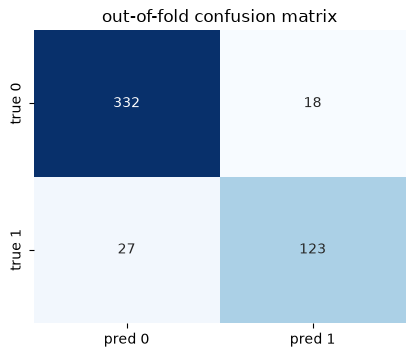

In [26]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report

y_oof = cross_val_predict(LogisticRegression(), X, y, cv=5)
cm = confusion_matrix(y, y_oof)
print(cm)
print(classification_report(y, y_oof, digits=3, target_names=["majority (0)", "minority (1)"]))
plt.figure(figsize=(4.8, 3.8)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=["pred 0", "pred 1"], yticklabels=["true 0", "true 1"]); plt.title("out-of-fold confusion matrix"); plt.show()

The pooled out-of-fold predictions contain 18 false positives and 27 false negatives; minority-class precision 0.872 and recall 0.820 match the fold-averaged 0.875 and 0.820 above (pooling and averaging differ slightly). Each of the 500 predictions came from a model that never saw that sample, so the matrix is an honest picture of the errors.

**Extension 3 — everything the grid search computed.** `best_score_` is only the top row of `cv_results_`:

In [27]:
cvr = pd.DataFrame(grid.cv_results_)[["param_C", "mean_test_score", "std_test_score", "rank_test_score", "mean_fit_time"]]
display(cvr.round(4).set_index("param_C"))
print("refit=True (default): best_estimator_ was refitted on ALL 500 samples ->", grid.best_estimator_)

,mean_test_score,std_test_score,rank_test_score,mean_fit_time
param_C,,,,
0.01,0.894,0.0206,4,0.0043
0.10,0.918,0.0360,1,0.0041
1.00,0.910,0.0341,2,0.0043
10.00,0.908,0.0366,3,0.0042


refit=True (default): best_estimator_ was refitted on ALL 500 samples -> LogisticRegression(C=0.1)


All four values of `C` score 0.894–0.918 with fold standard deviations of 0.02–0.04: the ranking (C = 0.1 first, then 1 and 10) is within noise, so the "best" `C` is the best of statistically tied candidates, and `best_score_` (0.918) is a slightly optimistic estimate of performance (Section 2, Extension 3). The refit model is trained on all 500 samples.

### Theory — the high-level API
* `cross_val_score(estimator, X, y, cv, scoring)` → one score per fold. `cross_validate` → dict of arrays (`test_<metric>`, `fit_time`, `score_time`, optionally `train_<metric>`, `estimator`). `cross_val_predict` → out-of-fold predictions. `GridSearchCV` / `RandomizedSearchCV` → search + CV + refit.
* **`cv` argument:** an int means (Stratified)KFold without shuffling (!) — pass a splitter with `shuffle=True` if the rows are ordered; or any splitter object.
* **Scoring:** pick the metric that matches the cost of errors; `scoring` strings that end in `neg_` are negated losses (greater is better), so that "higher is better" holds throughout.
* **Metrics for imbalance:** accuracy is dominated by the majority class; use balanced accuracy, precision/recall/F1 for the class that matters, ROC-AUC (ranking), average precision (precision–recall) or MCC.
* **Always compare with a dummy baseline** (`DummyClassifier`, `DummyRegressor`).

### Hands-on workflow (book)
Generate a classification dataset, create a baseline model such as `LogisticRegression`, use `cross_val_score()` for average accuracy, `cross_validate()` for several metrics, a parameter grid with `GridSearchCV()` for tuning, and interpret trends across metrics and configurations — as above.

## 4. Model selection techniques

**Summary.** After evaluating models by CV, the next step is choosing the best one (algorithm and configuration). The book compares the two hyper-parameter search strategies — exhaustive **grid search** and **randomized search** — then validates the winner on held-out test data. (The book also notes that in practice business rules and costs would influence the choice.)

### Getting ready

In [28]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV, train_test_split)
from sklearn.metrics import accuracy_score

In [29]:
X, y = make_classification(
    n_samples=500, n_features=10,
    weights=[0.7, 0.3], random_state=2024
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3,
    random_state=2024
)
print("train / test:", X_train.shape, X_test.shape)

train / test: (350, 10) (150, 10)


### How to do it…

In [30]:
param_grid = {"C": [0.001, 0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(
    LogisticRegression(), param_grid, cv=5,
    scoring='accuracy'
)
grid.fit(X_train, y_train)
print(f"GridSearchCV best C: {grid.best_params_['C']}")

GridSearchCV best C: 0.1

In [31]:
from scipy.stats import loguniform
param_dist = {"C": loguniform(1e-3, 1e2)}
random_search = RandomizedSearchCV(
    LogisticRegression(),
    param_distributions=param_dist,
    n_iter=10, cv=5, scoring='accuracy',
    random_state=2024
)
random_search.fit(X_train, y_train)
print(f"RandomizedSearchCV best C: "
      f"{random_search.best_params_['C']:.4f}")

RandomizedSearchCV best C: 0.1744


In [32]:
final_model = random_search.best_estimator_
y_pred = final_model.predict(X_test)
print(f"Final accuracy on test set: "
      f"{accuracy_score(y_test, y_pred):.3f}")

Final accuracy on test set: 0.940


**Verification against the book:** `GridSearchCV best C: 0.1`, `RandomizedSearchCV best C: 0.1744`, `Final accuracy on test set: 0.940` — all reproduced exactly ✔.

### How it works…
Grid search is exhaustive over the grid (expensive as parameters multiply); randomized search samples a fixed number of combinations from distributions — "often more efficient and yields comparable results with fewer evaluations". Let us check what was actually evaluated:

GridSearchCV evaluated      : 6 candidates x 5 folds = 30 fits
RandomizedSearchCV evaluated: 10 candidates x 5 folds = 50 fits


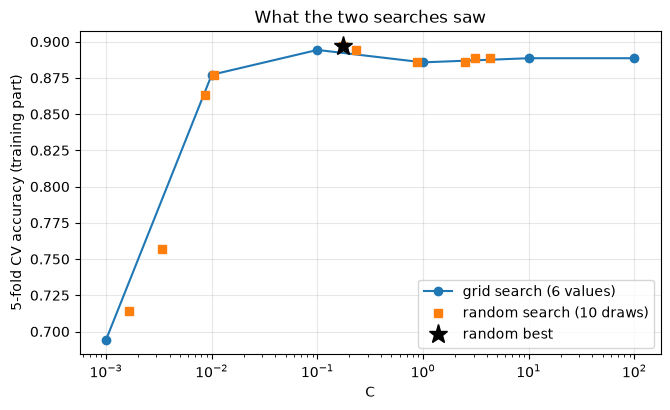

grid best CV accuracy 0.8943 (C=0.1) vs random best 0.8971 (C=0.1744)
test accuracy: grid-tuned 0.933 | random-tuned 0.940 | difference = 1 test sample(s) of 150
standard error of an accuracy near 0.94 on 150 test samples: 0.019


In [33]:
print("GridSearchCV evaluated      :", len(grid.cv_results_["params"]), "candidates x 5 folds =", len(grid.cv_results_["params"]) * 5, "fits")
print("RandomizedSearchCV evaluated:", len(random_search.cv_results_["params"]), "candidates x 5 folds =", len(random_search.cv_results_["params"]) * 5, "fits")

g = pd.DataFrame({"C": grid.cv_results_["param_C"].astype(float), "cv": grid.cv_results_["mean_test_score"]})
r = pd.DataFrame({"C": [p["C"] for p in random_search.cv_results_["params"]], "cv": random_search.cv_results_["mean_test_score"]}).sort_values("C")
plt.figure(figsize=(7.5, 4.2))
plt.semilogx(g["C"], g["cv"], "o-", label="grid search (6 values)")
plt.semilogx(r["C"], r["cv"], "s", color="C1", label="random search (10 draws)")
plt.semilogx(random_search.best_params_["C"], random_search.best_score_, "k*", ms=14, label="random best")
plt.xlabel("C"); plt.ylabel("5-fold CV accuracy (training part)"); plt.legend(); plt.grid(alpha=0.3); plt.title("What the two searches saw"); plt.show()

print(f"grid best CV accuracy {grid.best_score_:.4f} (C=0.1) vs random best {random_search.best_score_:.4f} (C={random_search.best_params_['C']:.4f})")
acc_g = accuracy_score(y_test, grid.best_estimator_.predict(X_test)); acc_r = accuracy_score(y_test, final_model.predict(X_test))
print(f"test accuracy: grid-tuned {acc_g:.3f} | random-tuned {acc_r:.3f} | difference = {round((acc_r - acc_g) * len(y_test))} test sample(s) of {len(y_test)}")
print(f"standard error of an accuracy near 0.94 on {len(y_test)} test samples: {np.sqrt(0.94 * 0.06 / len(y_test)):.3f}")

Randomized search evaluated **10** candidates (50 fits) while grid search evaluated only **6** (30 fits): here the random search was *more* expensive, not "fewer evaluations" as the book says — its advantage appears with many parameters, not with one. Both found the same plateau (best CV accuracy 0.8943 for the grid at `C = 0.1`, 0.8971 for the random search at `C = 0.17`; from `C = 0.01` to 100 the CV accuracy stays between 0.877 and 0.894 — see the figure). The final test accuracies, 0.933 vs 0.940, differ by **one** of 150 test samples while the standard error is 0.019: the book's "Final accuracy on test set: 0.940" is not evidence that either search is better.

**Extension — how much does the random search itself vary?** Repeat the randomized search with 20 different seeds: chosen `C`, CV score and test accuracy.

In [34]:
rows = []
for seed in range(20):
    rs = RandomizedSearchCV(LogisticRegression(), param_dist, n_iter=10, cv=5, scoring='accuracy', random_state=seed).fit(X_train, y_train)
    rows.append({"seed": seed, "chosen C": rs.best_params_["C"], "best CV accuracy": rs.best_score_, "test accuracy": accuracy_score(y_test, rs.best_estimator_.predict(X_test))})
rep = pd.DataFrame(rows).set_index("seed")
display(rep.describe().loc[["mean", "std", "min", "max"]].round(4))
print("chosen C ranged over", f"{rep['chosen C'].min():.3f} to {rep['chosen C'].max():.3f}", "| distinct test accuracies:", sorted(rep["test accuracy"].round(3).unique()))

,chosen C,best CV accuracy,test accuracy
mean,0.0730,0.9014,0.9357
std,0.0761,0.0050,0.0045
min,0.0184,0.8914,0.9267
max,0.3108,0.9086,0.9467


chosen C ranged over 0.018 to 0.311 | distinct test accuracies: [np.float64(0.927), np.float64(0.933), np.float64(0.94), np.float64(0.947)]


With 20 seeds the chosen `C` ranges from 0.018 to 0.31 (mean 0.073): the search result is itself random. The best CV accuracy is 0.901 ± 0.005 and the test accuracy 0.927–0.947 (mean 0.936 ± 0.0045) — only four distinct values (139 to 142 of 150 correct). "Best C = 0.1744" is not a number to quote to four digits: any value on the plateau is as good.

### Theory — model selection
* **Grid search** is exhaustive and reproducible but its cost multiplies with every parameter; **random search** (Bergstra & Bengio) is more efficient when only a few parameters matter, since it tries *distinct values of every parameter* each draw; draw scale parameters from a **log-uniform** distribution (as here).
* **Both are non-adaptive.** (Successive halving — `HalvingGridSearchCV` — and Bayesian optimisation adapt.)
* **The workflow:** split off a test set → tune by CV on the training part → refit → evaluate **once** on the test set. If the test set is used to choose between candidates it is no longer an unbiased estimate (nested CV removes the need for a separate test set when data are scarce).
* **Plateaus are normal:** many configurations tie within noise; prefer the simplest (strongest regularisation) among equals — the "one-standard-error rule".

### Hands-on workflow (book)
Generate a classification dataset, split it, set up a grid for logistic regression with `GridSearchCV()`, use `RandomizedSearchCV()` with a continuous distribution, compare the test performance of both tuned models and reflect on the time/accuracy trade-off — as above.

## 5. Evaluating model generalizability

**Summary.** A model that does well on training and validation data may still fail on unseen data — and, once in production, data drift makes today's good model tomorrow's poor one (hence MLOps: continuous monitoring and retraining). Two diagnostics assess generalisation: **learning curves** (score vs training-set size) and **validation curves** (score vs a hyper-parameter, i.e. model complexity).

### Getting ready
A larger dataset: 1,000 samples, 20 features, 70/30 class weights.

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    learning_curve, validation_curve)

In [36]:
X, y = make_classification(
    n_samples=1000, n_features=20,
    weights=[0.7, 0.3], random_state=2024
)
print("X:", X.shape, "| class counts:", np.bincount(y))

X: (1000, 20) | class counts: [695 305]


> **Book correction (a typesetting slip).** The printed import contains `validation_ curve` (with a space), which would be a `SyntaxError` if copied.

### How to do it…
**1. Learning curve**

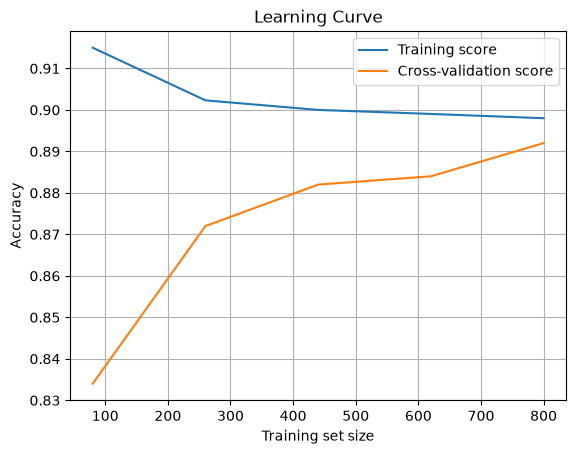

training sizes: [ 80 260 440 620 800]
training score: [0.915 0.902 0.9   0.899 0.898]
CV score      : [0.834 0.872 0.882 0.884 0.892]


In [37]:
train_sizes, train_scores, test_scores = learning_curve(
    LogisticRegression(), X, y, cv=5,
    scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 5),
    random_state=2024
)
train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
plt.plot(train_sizes, train_mean,
         label='Training score')
plt.plot(train_sizes, test_mean,
         label='Cross-validation score')
plt.xlabel('Training set size')
plt.ylabel('Accuracy')
plt.title('Learning Curve')
plt.legend()
plt.grid(True)
plt.show()
print("training sizes:", train_sizes)
print("training score:", train_mean.round(3))
print("CV score      :", test_mean.round(3))

**Verification against the book:** Figure 12.1 is reproduced: training sizes 80 → 800, the training score falls from 0.915 to 0.898, the cross-validation score climbs from 0.834 to 0.892 ✔.

The book says the training score "stays relatively flat even as the size of the dataset grows". It does not: it *decreases* by almost 2 points (0.915 → 0.898) — the standard behaviour: a model fits 80 points more easily than 800. The book is right that the two curves converge (gap 0.081 → 0.006), but note that the x-axis stops at **800**, not 1,000: each fold trains on 80% of the data, and `random_state=2024` has no effect here (it is used only when `shuffle=True`).

**2. Validation curve** — accuracy against the inverse regularisation strength `C`:

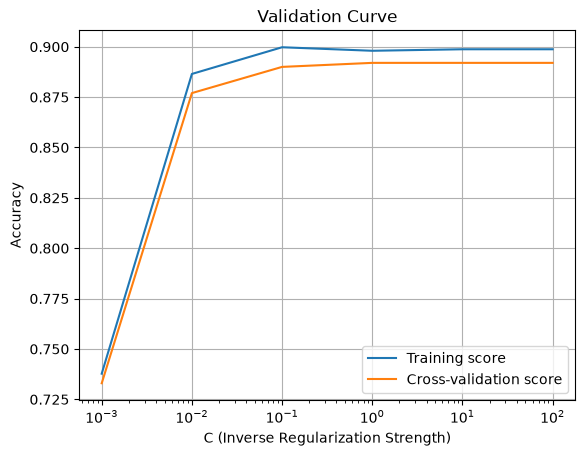

C        : [1.e-03 1.e-02 1.e-01 1.e+00 1.e+01 1.e+02]
training : [0.738 0.887 0.9   0.898 0.899 0.899]
CV score : [0.733 0.877 0.89  0.892 0.892 0.892]


In [38]:
param_range = np.logspace(-3, 2, 6)
train_scores, test_scores = validation_curve(
    LogisticRegression(), X, y, param_name="C",
    param_range=param_range, cv=5, scoring='accuracy'
)
train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
plt.semilogx(param_range, train_mean,
             label='Training score')
plt.semilogx(param_range, test_mean,
             label='Cross-validation score')
plt.xlabel('C (Inverse Regularization Strength)')
plt.ylabel('Accuracy')
plt.title('Validation Curve')
plt.legend()
plt.grid(True)
plt.show()
print("C        :", param_range)
print("training :", train_mean.round(3))
print("CV score :", test_mean.round(3))

**Verification against the book:** Figure 12.2 is reproduced: with `C = 0.001` strong regularisation under-fits (training 0.738, CV 0.733), both curves jump at `C = 0.01` (0.887 / 0.877) and plateau from `C ≈ 0.1` (CV 0.890–0.892) ✔ — "diminishing returns".

### How it works…
The learning curve shows how training and validation accuracy evolve with more data; a persistent gap signals over-fitting (high variance), convergence at a low level signals under-fitting (high bias). The validation curve shows under-/over-fitting along model complexity: small `C` (strong regularisation) may under-fit, large `C` may over-fit.
In this dataset the *large-C over-fitting never appears*: from `C = 1` to `C = 100` the training–validation gap stays below 0.01. A 20-feature, 800-sample logistic regression has too little capacity to over-fit. To *see* both diagnostics fail, and to read the error bars the book's lines hide, here are extensions:

**Extension 1 — the learning curve with its uncertainty,** shuffled folds, and the gap per size:

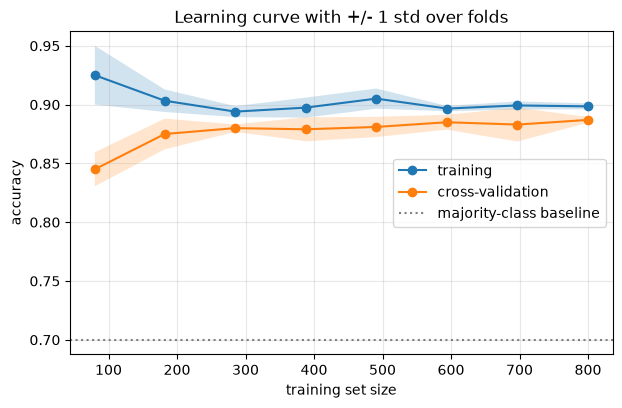

            train     CV    gap  CV std
train size                             
80          0.925  0.845  0.080   0.014
182         0.903  0.875  0.028   0.013
285         0.894  0.880  0.014   0.003
388         0.897  0.879  0.018   0.010
491         0.905  0.881  0.024   0.009
594         0.897  0.885  0.012   0.006
697         0.899  0.883  0.016   0.014
800         0.898  0.887  0.012   0.002


In [39]:
from sklearn.model_selection import StratifiedKFold

ts, tr, te = learning_curve(LogisticRegression(), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="accuracy",
                            train_sizes=np.linspace(0.1, 1.0, 8))
fig, ax = plt.subplots(figsize=(7, 4.2))
for arr, lab in [(tr, "training"), (te, "cross-validation")]:
    m, s = arr.mean(axis=1), arr.std(axis=1)
    ax.plot(ts, m, "o-", label=lab); ax.fill_between(ts, m - s, m + s, alpha=0.2)
ax.axhline(0.7, color="gray", ls=":", label="majority-class baseline"); ax.set_xlabel("training set size"); ax.set_ylabel("accuracy"); ax.legend(); ax.grid(alpha=0.3); ax.set_title("Learning curve with +/- 1 std over folds")
plt.show()
print(pd.DataFrame({"train size": ts, "train": tr.mean(axis=1).round(3), "CV": te.mean(axis=1).round(3), "gap": (tr.mean(axis=1) - te.mean(axis=1)).round(3), "CV std": te.std(axis=1).round(3)}).set_index("train size"))

With eight sizes and shuffled folds the training–validation gap shrinks from 0.080 (80 samples) to 0.012 (800), and the fold standard deviation of the CV score is 0.002–0.014. The majority-class baseline is 0.70, so the model is ≈ 19 points above it even at 800 samples. The curves *converge* — but see Extension 3 for the level at which they converge.

**Extension 2 — a model that *does* over-fit.** The same two diagnostics for a decision tree (complexity = `max_depth`) on the same data:

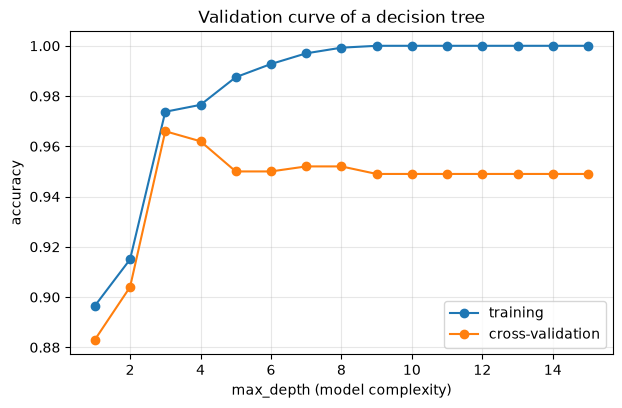

best max_depth by CV: 3 | CV accuracy: 0.966 | training accuracy at that depth: 0.974
at max_depth=15: training 1.0 | CV 0.949


In [40]:
from sklearn.tree import DecisionTreeClassifier

depths = np.arange(1, 16)
tr_d, te_d = validation_curve(DecisionTreeClassifier(random_state=0), X, y, param_name="max_depth", param_range=depths, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="accuracy")
plt.figure(figsize=(7, 4.2))
plt.plot(depths, tr_d.mean(axis=1), "o-", label="training"); plt.plot(depths, te_d.mean(axis=1), "o-", label="cross-validation")
plt.xlabel("max_depth (model complexity)"); plt.ylabel("accuracy"); plt.legend(); plt.grid(alpha=0.3); plt.title("Validation curve of a decision tree"); plt.show()
best = int(depths[te_d.mean(axis=1).argmax()])
print("best max_depth by CV:", best, "| CV accuracy:", te_d.mean(axis=1).max().round(3), "| training accuracy at that depth:", tr_d.mean(axis=1)[best - 1].round(3))
print("at max_depth=15: training", tr_d.mean(axis=1)[-1].round(3), "| CV", te_d.mean(axis=1)[-1].round(3))

The decision tree over-fits visibly at depth 15 (training accuracy 1.00, CV 0.949) but peaks at **depth 3 with CV accuracy 0.966** (training 0.974) — 7.6 points better than the logistic regression's 0.89. The validation curve shows the complete picture that the book's `C` curve cannot: the CV score rises to a maximum and then falls while the training score keeps rising.

**Extension 3 — "converged" is not the same as "good".** The logistic regression's curves converge, but at 0.89. Other models on the same data and the same folds:

In [41]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier

cv_ = StratifiedKFold(5, shuffle=True, random_state=0)
rows = {}
for name, est in [("majority baseline", DummyClassifier()), ("LogisticRegression (the book's model)", LogisticRegression()), ("DecisionTree(max_depth=3)", DecisionTreeClassifier(max_depth=3, random_state=0)),
                  ("SVC (RBF)", SVC()), ("KNeighbors (k=5)", KNeighborsClassifier()), ("RandomForest (200 trees)", RandomForestClassifier(200, random_state=0))]:
    sc = cross_val_score(est, X, y, cv=cv_)
    rows[name] = {"CV accuracy": sc.mean(), "std": sc.std()}
display(pd.DataFrame(rows).T.round(3))

,CV accuracy,std
majority baseline,0.695,0.000
LogisticRegression (the book's model),0.887,0.002
DecisionTree(max_depth=3),0.966,0.006
SVC (RBF),0.951,0.014
KNeighbors (k=5),0.901,0.015
RandomForest (200 trees),0.969,0.005


The logistic regression's plateau at 0.887 reflects its *capacity* (high bias), not "good generalisation": a depth-3 tree reaches 0.966, a random forest 0.969 and an RBF SVM 0.951 on the same folds. Converged curves tell you that **more data will not help this model**; they do not tell you that the model is adequate. Learning and validation curves diagnose a given model — comparing models needs other models.

### There's more… (book hands-on)
The book's workflow: generate a classification dataset, use `learning_curve()` and `validation_curve()` to plot training vs validation scores, interpret over-/under-fitting, and use the insights to guide further data collection or tuning (done above).

### Theory — learning and validation curves
* **Learning curve** (x = training size): *high bias* → both curves converge to a *low* score (more data will not help — a more flexible model will); *high variance* → a large gap that narrows slowly (more data, regularisation or a simpler model will help).
* **Validation curve** (x = complexity): under-fitting on the left (both scores low), over-fitting on the right (training high, validation falling); choose the complexity at the peak of the validation curve.
* **Report uncertainty** (std over folds) and compare with the dummy baseline.
* **Generalisation in production** also depends on *distribution shift*: CV only estimates performance on data like the training data, so monitor the live performance and retrain (MLOps; Chapter 13).

### Hands-on workflow (book)
See above: curves for training size and for `C`, interpretation, and the decision on data collection vs tuning.

## 6. Practical exercises in cross-validation and evaluation

The book lists three exercises with implementation steps only (no code). They are implemented here on the Breast Cancer and digits datasets (the book does not name a dataset).

### Exercise 1: Cross-validating a logistic regression model
Steps (book): load the libraries, load the dataset, cross-validate and collect metrics. The scaler sits inside the `Pipeline` so that each fold scales with its own training statistics.

In [42]:
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_validate, StratifiedKFold

Xb, yb = load_breast_cancer(return_X_y=True)
print("Breast Cancer:", Xb.shape, "| class counts (malignant, benign):", np.bincount(yb))

pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)
res = cross_validate(pipe, Xb, yb, cv=cv, scoring=["accuracy", "precision", "recall", "f1", "roc_auc"], return_train_score=True)
tab = pd.DataFrame({m: {"test mean": res[f"test_{m}"].mean(), "test std": res[f"test_{m}"].std(), "train mean": res[f"train_{m}"].mean()} for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]}).T
display(tab.round(3))
print("per-fold test accuracy:", res["test_accuracy"].round(3), "| fit time per fold (s):", res["fit_time"].round(3))

from sklearn.metrics import make_scorer, recall_score
r0 = cross_validate(pipe, Xb, yb, cv=cv, scoring={"recall of class 0 (malignant)": make_scorer(recall_score, pos_label=0), "recall of class 1 (benign)": make_scorer(recall_score, pos_label=1)})
print("precision/recall above refer to class 1 (benign, the majority). Recall per class:", {k[5:]: round(v.mean(), 3) for k, v in r0.items() if k.startswith("test_")})

Breast Cancer: (569, 30) | class counts (malignant, benign): [212 357]


,test mean,test std,train mean
accuracy,0.975,0.018,0.989
precision,0.968,0.029,0.986
recall,0.994,0.007,0.997
f1,0.981,0.014,0.991
roc_auc,0.996,0.004,0.998


per-fold test accuracy: [1.    0.965 0.982 0.947 0.982] | fit time per fold (s): [0.011 0.009 0.009 0.008 0.011]


precision/recall above refer to class 1 (benign, the majority). Recall per class: {'recall of class 0 (malignant)': np.float64(0.943), 'recall of class 1 (benign)': np.float64(0.994)}


5-fold CV: accuracy **0.975 ± 0.018**, ROC-AUC 0.996; training accuracy 0.989, a gap of 1.4 points (mild over-fitting). The printed precision/recall refer to class 1 (*benign*, the majority, 63%); for a screening task the sensitivity to the *malignant* class matters, shown on the last line: the recall of class 0 is **0.943** (≈ 6% of malignant tumours missed) against 0.994 for benign ones. A pipeline keeps the scaler inside each fold, so no information leaks from the validation folds.

### Exercise 2: Tuning hyperparameters with grid search
Steps (book): load the libraries, load and split the dataset, perform grid search, evaluate on the test set. Beyond the book: the full search table and a nested-CV estimate to compare with the test-set number.

In [43]:
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.svm import SVC

Xtr, Xte, ytr, yte = train_test_split(Xb, yb, test_size=0.25, stratify=yb, random_state=2024)
pipe2 = make_pipeline(StandardScaler(), SVC())
grid2 = GridSearchCV(pipe2, {"svc__C": [0.1, 1, 10, 100], "svc__gamma": ["scale", 0.001, 0.01, 0.1]}, cv=5, scoring="accuracy").fit(Xtr, ytr)
print("best parameters:", grid2.best_params_, "| best CV accuracy:", round(grid2.best_score_, 4))
print("test accuracy of the refitted best model:", round(grid2.score(Xte, yte), 4), f"(n = {len(yte)}, standard error about {np.sqrt(0.97 * 0.03 / len(yte)):.3f})")

top = pd.DataFrame(grid2.cv_results_).sort_values("rank_test_score")[["params", "mean_test_score", "std_test_score", "rank_test_score"]].head(6)
display(top.round(4).set_index("rank_test_score"))
print("configurations within one standard error of the best:", int((pd.DataFrame(grid2.cv_results_)["mean_test_score"] >= grid2.best_score_ - grid2.cv_results_["std_test_score"][grid2.best_index_]).sum()), "of 16")

nested = cross_val_score(GridSearchCV(pipe2, {"svc__C": [0.1, 1, 10, 100], "svc__gamma": ["scale", 0.001, 0.01, 0.1]}, cv=5), Xb, yb, cv=StratifiedKFold(5, shuffle=True, random_state=1))
print("nested CV accuracy on all 569 samples:", nested.round(3), "| mean", nested.mean().round(4))

best parameters: {'svc__C': 10, 'svc__gamma': 'scale'} | best CV accuracy: 0.9812
test accuracy of the refitted best model: 0.958 (n = 143, standard error about 0.014)


,params,mean_test_score,std_test_score
rank_test_score,,,
1,"{'svc__C': 10, 'svc__gamma': 'scale'}",0.9812,0.0094
2,"{'svc__C': 100, 'svc__gamma': 0.001}",0.9765,0.0106
3,"{'svc__C': 10, 'svc__gamma': 0.01}",0.9741,0.0088
3,"{'svc__C': 100, 'svc__gamma': 0.01}",0.9741,0.0188
5,"{'svc__C': 1, 'svc__gamma': 0.01}",0.9741,0.0228
6,"{'svc__C': 100, 'svc__gamma': 'scale'}",0.9718,0.0120


configurations within one standard error of the best: 7 of 16


nested CV accuracy on all 569 samples: [0.982 0.982 0.982 0.965 0.965] | mean 0.9754


The search picks `C = 10, gamma = 'scale'` (CV accuracy 0.981). The held-out test accuracy is 0.958 (137 of 143), below the CV estimate but within about 1.5 standard errors (0.014) — a single small test set is itself a noisy estimate. The nested-CV accuracy (0.975, on all 569 samples) is a more stable estimate of "tune, then fit". The table shows how many configurations are statistically tied: 7 of the 16 lie within one standard error of the best, so the best parameters are one of several equally good choices.

### Exercise 3: Assessing model generalization with learning and validation curves
Steps (book): load the libraries, plot the learning curve, plot the validation curve. With the 64-dimensional digits dataset and an RBF SVM, the validation curve over `gamma` shows genuine over-fitting:

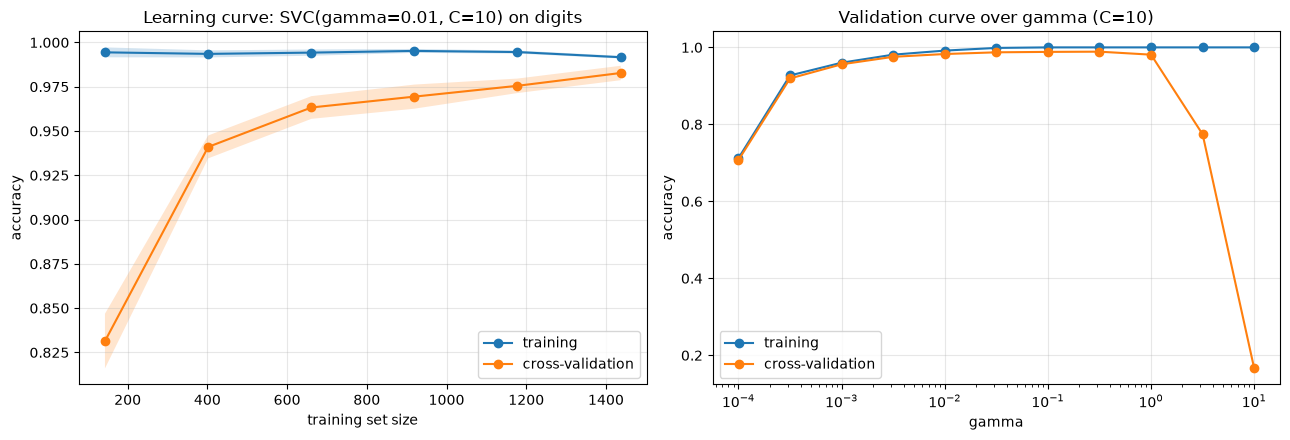

learning curve  CV: [0.831 0.941 0.963 0.969 0.976 0.983] | train: [0.994 0.994 0.994 0.995 0.995 0.992]
gamma  0.00010   0.00032   0.00100   0.00316   0.01000   0.03162   0.10000   \
train     0.712     0.927     0.960     0.981     0.992     0.999     1.000   
CV        0.707     0.919     0.956     0.976     0.983     0.987     0.988   

gamma  0.31623   1.00000   3.16228   10.00000  
train     1.000     1.000     1.000     1.000  
CV        0.989     0.981     0.774     0.166  


In [44]:
from sklearn.datasets import load_digits

Xd, yd = load_digits(return_X_y=True)
Xd = Xd / 16.0                                                    # pixel values 0..16 -> 0..1

ts, tr, te = learning_curve(SVC(gamma=0.01, C=10), Xd, yd, cv=StratifiedKFold(5, shuffle=True, random_state=0), train_sizes=np.linspace(0.1, 1.0, 6))
gammas = np.logspace(-4, 1, 11)
trv, tev = validation_curve(SVC(C=10), Xd, yd, param_name="gamma", param_range=gammas, cv=StratifiedKFold(5, shuffle=True, random_state=0))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for arr, lab in [(tr, "training"), (te, "cross-validation")]:
    m, s = arr.mean(axis=1), arr.std(axis=1); ax[0].plot(ts, m, "o-", label=lab); ax[0].fill_between(ts, m - s, m + s, alpha=0.2)
ax[0].set_xlabel("training set size"); ax[0].set_ylabel("accuracy"); ax[0].set_title("Learning curve: SVC(gamma=0.01, C=10) on digits"); ax[0].legend(); ax[0].grid(alpha=0.3)
for arr, lab in [(trv, "training"), (tev, "cross-validation")]:
    ax[1].semilogx(gammas, arr.mean(axis=1), "o-", label=lab)
ax[1].set_xlabel("gamma"); ax[1].set_ylabel("accuracy"); ax[1].set_title("Validation curve over gamma (C=10)"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("learning curve  CV:", te.mean(axis=1).round(3), "| train:", tr.mean(axis=1).round(3))
print(pd.DataFrame({"gamma": gammas.round(5), "train": trv.mean(axis=1).round(3), "CV": tev.mean(axis=1).round(3)}).set_index("gamma").T)

**Learning curve** (`SVC(gamma=0.01, C=10)`): CV accuracy rises from 0.831 (143 training samples) to 0.983 (1,437) while the training accuracy stays near 0.99: the gap shrinks from 0.16 to 0.01 and the CV curve is still rising slightly at the right end. **Validation curve over `gamma`**: under-fitting at `gamma = 1e-4` (0.71 / 0.71), the best CV accuracy of **0.989 at `gamma ≈ 0.3`**, and then spectacular **over-fitting**: the training accuracy stays at 1.000 while the CV accuracy collapses to 0.774 (`gamma = 3.2`) and 0.166 (`gamma = 10`; chance for ten classes is 0.10). This is the picture the book's logistic-regression validation curve — which never over-fits — cannot show.

## Chapter takeaways
1. **A single split is noisy; cross-validation averages *k* of them** and the spread over folds tells you how much to trust the number. A 1-point difference between two CV runs (the book's 0.756 vs 0.766) is within the shuffle-to-shuffle noise (std ≈ 0.006 over 300 repeats; both strategies average 0.770).
2. **Stratification matters for rare classes** (38% of plain 5-fold splits of a 10%-positive dataset had a fold without positives), not for balanced data. `cv=5` with a classifier is *already* stratified.
3. **LOOCV** is nearly unbiased but costs *n* fits (Ridge has a closed-form shortcut: `RidgeCV` gave the identical MSE 3,327.655 in ≈ 2 ms). **Nested CV** estimates "tune, then fit" without selection bias: on pure noise the same-fold `best_score_` was 0.579, nested 0.516.
4. **Leakage is the bigger trap:** feature selection before CV turned random labels into 0.81 accuracy; inside a `Pipeline` it is 0.43 (≈ chance). Groups and time series need `GroupKFold` / `TimeSeriesSplit`.
5. **Read the numbers correctly:** the nested CV 0.480 is an R² (MSE ≈ 3,005, half of the variance 5,930) — not "0.593 MSE, no better than guessing". Compare accuracy with the majority baseline (0.70) and use balanced accuracy, precision/recall, ROC-AUC or average precision for imbalance.
6. **Search is noisy too:** grid (6 candidates) and random search (10 candidates — more, not fewer, fits) found the same plateau; the chosen `C` ranged over 0.018–0.31 across seeds and the "final" 0.940 vs 0.933 was one test sample.
7. **Learning and validation curves diagnose a model:** the logistic regression converges at 0.89 (bias-limited — a depth-3 tree gets 0.966); over-fitting only appears for models with enough capacity (decision tree depth, SVM `gamma`: training 1.0, CV 0.17).

### Book corrections noted in this notebook
| Where | Book says / does | Actually |
|---|---|---|
| Chapter introduction | lists a recipe "Model evaluation metrics overview" | no such recipe exists in the chapter (added here as an extension) |
| Stratified vs plain k-fold | "stratified actually elicits a slightly higher accuracy, which is good news" (0.766 vs 0.756) | a 1-point difference between two draws; the dataset is balanced; over 300 shuffles both average 0.770 (std 0.006) |
| Diabetes target | "a qualitative target variable" | quantitative (continuous, 25–346) |
| Nested CV result | "our final 0.593 MSE is not much better than guessing" | no 0.593 anywhere; 0.480 is an **R²**; MSE ≈ 3,005 vs the variance 5,930 (guessing the mean) — about half |
| LOOCV vs nested | presented side by side | different tuning (`alpha=1` fixed vs tuned) and different units (MSE vs R²): not comparable |
| Stratification in Recipe 3 | "we didn't [stratify] and our dataset is imbalanced" | `cv=5` with a classifier uses `StratifiedKFold` automatically |
| Metrics comparison | "accuracy is the highest performing metric" | the metrics measure different things; compare with the majority baseline (0.70) |
| Random vs grid search | "yields comparable results with fewer evaluations" | 10 candidates (50 fits) vs 6 (30 fits); chosen `C` varies 0.018–0.31 across seeds |
| "Final accuracy 0.940" | presented as the tuned result | one test sample (of 150) better than the grid-tuned 0.933; standard error 0.019 |
| Learning curve | "the training score stays relatively flat" | it falls from 0.915 to 0.898; the x axis ends at 800 (not 1,000); `random_state` has no effect without `shuffle=True` |
| Convergence | converged curves → good generalisation | they converge at 0.89, limited by the model: a depth-3 tree reaches 0.966 |
| Validation curve | large `C` "may cause overfitting" | not visible: the train–CV gap stays < 0.01 up to `C=100` (over-fitting is shown with tree depth / SVM `gamma`) |
| `validation_ curve` | in the import list | stray space — a `SyntaxError` if copied |

*Chapters 1–12 are complete.*